# Compensation and Satisfaction: an HR portfolio diagnostic

**Scope:** compensation architecture, pay distribution, job satisfaction and work-life balance.

The dataset contains employee-level records across three departments, nine job roles and five job levels. The analysis treats compensation at the employee grain, uses medians for group benchmarking, and separates descriptive patterns from statistical evidence.

Attrition is outside this study. The attrition field is excluded from the analytical dataset, and no attrition outcomes are modelled.

## Analytical frame

Three questions organize the work:

- **Where does compensation sit?** Department, role, level and gender comparisons, with the median as the principal benchmark.
- **Where do experience gaps appear?** Job satisfaction and work-life balance distributions, including the low-satisfaction share and the lowest work-life balance category.
- **Do the patterns move together?** Correlation, group comparisons and an exploratory adjusted pay model provide context without implying causation.

A single employee is the unit of analysis. Each person contributes once to compensation medians; no daily or repeated fact grain is involved.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, kruskal, mannwhitneyu, ttest_ind
from statsmodels.stats.proportion import proportion_confint
import statsmodels.formula.api as smf
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "#F7F9FC",
    "axes.facecolor": "#F7F9FC",
    "axes.edgecolor": "#D9E0EA",
    "axes.labelcolor": "#25344A",
    "text.color": "#17263C",
    "xtick.color": "#536278",
    "ytick.color": "#536278",
    "font.family": "DejaVu Sans",
    "axes.titleweight": "bold",
    "axes.titlesize": 15,
    "axes.labelsize": 10,
    "figure.titlesize": 19,
})

NAVY = "#17324D"
BLUE = "#3478A8"
TEAL = "#2A9D8F"
GOLD = "#E9B44C"
CORAL = "#E76F51"
PURPLE = "#8067A9"
MUTED = "#7D8CA1"
PALETTE = [NAVY, BLUE, TEAL, GOLD, CORAL, PURPLE]

print("Analysis libraries loaded.")

Analysis libraries loaded.


## Source file and data integrity

The source is the supplied IBM HR Analytics employee dataset. The local Windows path is retained in the notebook so the same file can be read directly from the Desktop in the user's VS Code environment.

The original file has 35 columns. Five fields are outside the analytical scope: the attrition outcome, employee identifier, constant employee count, constant age-eligibility flag and constant standard-hours field.

In [2]:
file_path = Path(r"C:\Users\anarrasulzada\Desktop\WA_Fn-UseC_-HR-Employee-Attrition.csv")
raw = pd.read_csv(file_path)

print(f"Dataset: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())

Dataset: 1,470 rows × 35 columns


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
quality_summary = pd.DataFrame({
    "Check": [
        "Rows",
        "Columns",
        "Missing cells",
        "Duplicate rows",
        "Unique employee numbers",
        "Unique departments",
        "Unique job roles",
        "Unique job levels",
    ],
    "Result": [
        len(raw),
        raw.shape[1],
        int(raw.isna().sum().sum()),
        int(raw.duplicated().sum()),
        int(raw["EmployeeNumber"].nunique()),
        int(raw["Department"].nunique()),
        int(raw["JobRole"].nunique()),
        int(raw["JobLevel"].nunique()),
    ],
})

display(quality_summary)
display(raw.dtypes.rename("Data type").to_frame().T)

,Check,Result
0,Rows,1470
1,Columns,35
2,Missing cells,0
3,Duplicate rows,0
4,Unique employee numbers,1470
5,Unique departments,3
6,Unique job roles,9
7,Unique job levels,5


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
Data type,int64,object,object,int64,object,int64,int64,object,int64,int64,int64,object,int64,int64,int64,object,int64,object,int64,int64,int64,object,object,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64


## Scope and analytical fields

The working table excludes the five out-of-scope or non-informative fields. The source remains unchanged in `raw`; the scoped table is `hr`.

`MonthlyIncome` is treated as a numeric dataset amount. The source does not provide a currency declaration, so charts and tables avoid attaching an unsupported currency symbol. Satisfaction and work-life balance scores are ordinal scales from 1 to 4.

In [4]:
excluded_columns = [
    "Attrition",
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours",
]

hr = raw.drop(columns=excluded_columns).copy()

satisfaction_labels = {
    1: "1 · Low",
    2: "2 · Moderate",
    3: "3 · High",
    4: "4 · Very high",
}
worklife_labels = {
    1: "1 · Bad",
    2: "2 · Good",
    3: "3 · Better",
    4: "4 · Best",
}

hr["JobSatisfactionLabel"] = hr["JobSatisfaction"].map(satisfaction_labels)
hr["WorkLifeBalanceLabel"] = hr["WorkLifeBalance"].map(worklife_labels)

print("Scoped analytical rows:", len(hr))
print("Excluded source fields:", ", ".join(excluded_columns))
print("Departments:", ", ".join(sorted(hr["Department"].unique())))
print("Job roles:", hr["JobRole"].nunique())

Scoped analytical rows: 1470
Excluded source fields: Attrition, EmployeeNumber, EmployeeCount, Over18, StandardHours
Departments: Human Resources, Research & Development, Sales
Job roles: 9


## Compensation architecture

The median is the main measure of typical pay. Monthly income is right-skewed, so the mean is more exposed to a small number of senior and high-income observations.

The tables below compare departments, roles, levels and gender. The department-by-level pivot makes the pay ladder visible, while role-level ratios describe the spread between the highest and lowest median-paid roles inside each department.

In [5]:
department_comp = (
    hr.groupby("Department")
      .agg(
          employees=("MonthlyIncome", "size"),
          median_income=("MonthlyIncome", "median"),
          q25_income=("MonthlyIncome", lambda s: s.quantile(0.25)),
          q75_income=("MonthlyIncome", lambda s: s.quantile(0.75)),
          mean_income=("MonthlyIncome", "mean"),
      )
      .sort_values("median_income", ascending=False)
      .reset_index()
)

role_comp = (
    hr.groupby(["Department", "JobRole"])
      .agg(
          employees=("MonthlyIncome", "size"),
          median_income=("MonthlyIncome", "median"),
          q25_income=("MonthlyIncome", lambda s: s.quantile(0.25)),
          q75_income=("MonthlyIncome", lambda s: s.quantile(0.75)),
      )
      .reset_index()
      .sort_values(["Department", "median_income"], ascending=[True, False])
)

level_comp = (
    hr.groupby("JobLevel")
      .agg(
          employees=("MonthlyIncome", "size"),
          median_income=("MonthlyIncome", "median"),
          mean_income=("MonthlyIncome", "mean"),
      )
      .reset_index()
)

gender_overall = (
    hr.groupby("Gender")
      .agg(
          employees=("MonthlyIncome", "size"),
          median_income=("MonthlyIncome", "median"),
          mean_income=("MonthlyIncome", "mean"),
      )
      .reset_index()
)

gender_comp = (
    hr.groupby(["Department", "Gender"])
      .agg(
          employees=("MonthlyIncome", "size"),
          median_income=("MonthlyIncome", "median"),
      )
      .reset_index()
)

compensation_pivot = pd.pivot_table(
    hr,
    index="Department",
    columns="JobLevel",
    values="MonthlyIncome",
    aggfunc="median",
).reindex(columns=[1, 2, 3, 4, 5])

level_count_pivot = pd.pivot_table(
    hr,
    index="Department",
    columns="JobLevel",
    values="MonthlyIncome",
    aggfunc="count",
).reindex(columns=[1, 2, 3, 4, 5])

display(department_comp.round(1))
display(role_comp.round(1))
display(level_comp.round(1))
display(gender_overall.round(1))
display(gender_comp.round(1))
display(compensation_pivot.round(0))

,Department,employees,median_income,q25_income,q75_income,mean_income
0,Sales,446,5754.5,4446.2,8776.8,6959.2
1,Research & Development,961,4374.0,2741.0,7655.0,6281.3
2,Human Resources,63,3886.0,2644.0,8412.5,6654.5


,Department,JobRole,employees,median_income,q25_income,q75_income
1,Human Resources,Manager,11,18844.0,17063.5,19412.5
0,Human Resources,Human Resources,52,3093.0,2340.2,5803.5
4,Research & Development,Manager,54,17545.5,16581.0,19189.2
6,Research & Development,Research Director,80,16510.0,13490.2,18814.5
2,Research & Development,Healthcare Representative,131,6811.0,5562.0,9769.5
5,Research & Development,Manufacturing Director,145,6447.0,5070.0,9526.0
7,Research & Development,Research Scientist,292,2887.5,2386.0,3902.5
3,Research & Development,Laboratory Technician,259,2886.0,2379.5,3880.5
8,Sales,Manager,37,17048.0,16064.0,18789.0
9,Sales,Sales Executive,326,6231.0,5025.2,8538.8


,JobLevel,employees,median_income,mean_income
0,1,543,2670.0,2786.9
1,2,534,5340.0,5502.3
2,3,218,9980.0,9817.3
3,4,106,16154.0,15503.8
4,5,69,19232.0,19191.8


,Gender,employees,median_income,mean_income
0,Female,588,5081.5,6686.6
1,Male,882,4837.5,6380.5


,Department,Gender,employees,median_income
0,Human Resources,Female,20,4313.5
1,Human Resources,Male,43,3886.0
2,Research & Development,Female,379,4615.0
3,Research & Development,Male,582,4174.5
4,Sales,Female,189,5666.0
5,Sales,Male,257,6134.0


JobLevel,1,2,3,4,5
Department,,,,,
Human Resources,2696.0,5985.0,9853.0,16618.0,19189.0
Research & Development,2693.0,5228.0,10312.0,16370.0,19237.0
Sales,2553.0,5423.0,9250.0,15700.0,19068.0


In [6]:
role_extremes = (
    role_comp.groupby("Department")
    .apply(
        lambda g: pd.Series({
            "lowest_paid_role": g.loc[g["median_income"].idxmin(), "JobRole"],
            "lowest_role_median": g["median_income"].min(),
            "highest_paid_role": g.loc[g["median_income"].idxmax(), "JobRole"],
            "highest_role_median": g["median_income"].max(),
            "pay_gap_ratio": g["median_income"].max() / g["median_income"].min(),
        }),
        include_groups=False,
    )
    .reset_index()
)

income_mean = hr["MonthlyIncome"].mean()
income_median = hr["MonthlyIncome"].median()
income_skew = hr["MonthlyIncome"].skew()
joblevel_income_corr = hr["JobLevel"].corr(hr["MonthlyIncome"])

print(f"Company median monthly income: {income_median:,.0f}")
print(f"Company mean monthly income: {income_mean:,.0f}")
print(f"Income skewness: {income_skew:.2f}")
print(f"Pearson correlation: JobLevel vs MonthlyIncome = {joblevel_income_corr:.3f}")
display(role_extremes.round(2))

Company median monthly income: 4,919
Company mean monthly income: 6,503
Income skewness: 1.37
Pearson correlation: JobLevel vs MonthlyIncome = 0.950


,Department,lowest_paid_role,lowest_role_median,highest_paid_role,highest_role_median,pay_gap_ratio
0,Human Resources,Human Resources,3093.0,Manager,18844.0,6.09
1,Research & Development,Laboratory Technician,2886.0,Manager,17545.5,6.08
2,Sales,Sales Representative,2579.0,Manager,17048.0,6.61


## Satisfaction and work-life balance

The satisfaction profile is evaluated as a four-point distribution rather than reduced to a single average. The main risk flag is the share of employees scoring 1 or 2.

WorkLifeBalance uses the same four-point structure. The action flag compares the department share at score 1 with the company-wide score-1 share. Department sample sizes remain visible, particularly for Human Resources.

In [7]:
satisfaction_overall = (
    hr["JobSatisfaction"].value_counts()
      .reindex([1, 2, 3, 4], fill_value=0)
      .rename_axis("JobSatisfaction")
      .reset_index(name="employees")
)
satisfaction_overall["share_pct"] = satisfaction_overall["employees"] / len(hr) * 100

satisfaction_by_department = pd.crosstab(
    hr["Department"], hr["JobSatisfaction"], normalize="index"
).reindex(columns=[1, 2, 3, 4]).mul(100)

low_satisfaction = (
    hr.assign(low_satisfaction=hr["JobSatisfaction"].le(2))
      .groupby("Department")
      .agg(
          employees=("low_satisfaction", "size"),
          low_satisfaction_count=("low_satisfaction", "sum"),
          low_satisfaction_share=("low_satisfaction", "mean"),
      )
      .reset_index()
)
low_satisfaction["low_satisfaction_pct"] = low_satisfaction["low_satisfaction_share"] * 100
ci = low_satisfaction.apply(
    lambda row: proportion_confint(
        int(row["low_satisfaction_count"]), int(row["employees"]), method="wilson"
    ),
    axis=1,
)
low_satisfaction["ci_low_pct"] = [x[0] * 100 for x in ci]
low_satisfaction["ci_high_pct"] = [x[1] * 100 for x in ci]

display(satisfaction_overall.round(2))
display(satisfaction_by_department.round(1))
display(low_satisfaction.round(2))

,JobSatisfaction,employees,share_pct
0,1,289,19.66
1,2,280,19.05
2,3,442,30.07
3,4,459,31.22


JobSatisfaction,1,2,3,4
Department,,,,
Human Resources,17.5,31.7,23.8,27.0
Research & Development,20.0,18.1,31.2,30.7
Sales,19.3,19.3,28.5,33.0


,Department,employees,low_satisfaction_count,low_satisfaction_share,low_satisfaction_pct,ci_low_pct,ci_high_pct
0,Human Resources,63,31,0.49,49.21,37.27,61.24
1,Research & Development,961,366,0.38,38.09,35.07,41.20
2,Sales,446,172,0.39,38.57,34.16,43.16


In [8]:
worklife_overall = (
    hr["WorkLifeBalance"].value_counts()
      .reindex([1, 2, 3, 4], fill_value=0)
      .rename_axis("WorkLifeBalance")
      .reset_index(name="employees")
)
worklife_overall["share_pct"] = worklife_overall["employees"] / len(hr) * 100

worklife_by_department = pd.crosstab(
    hr["Department"], hr["WorkLifeBalance"], normalize="index"
).reindex(columns=[1, 2, 3, 4]).mul(100)

company_wlb1_share = hr["WorkLifeBalance"].eq(1).mean() * 100

worklife_flags = (
    hr.assign(wlb1=hr["WorkLifeBalance"].eq(1))
      .groupby("Department")
      .agg(
          employees=("wlb1", "size"),
          wlb1_count=("wlb1", "sum"),
          wlb1_share=("wlb1", "mean"),
      )
      .reset_index()
)
worklife_flags["wlb1_pct"] = worklife_flags["wlb1_share"] * 100
worklife_flags["company_reference_pct"] = company_wlb1_share
worklife_flags["difference_vs_company_pp"] = (
    worklife_flags["wlb1_pct"] - company_wlb1_share
)
worklife_flags["action_flag"] = (
    worklife_flags["wlb1_pct"] > company_wlb1_share
)

display(worklife_overall.round(2))
display(worklife_by_department.round(1))
display(worklife_flags.round(2))

,WorkLifeBalance,employees,share_pct
0,1,80,5.44
1,2,344,23.40
2,3,893,60.75
3,4,153,10.41


WorkLifeBalance,1,2,3,4
Department,,,,
Human Resources,6.3,11.1,66.7,15.9
Research & Development,6.2,24.5,59.8,9.5
Sales,3.6,22.9,61.9,11.7


,Department,employees,wlb1_count,wlb1_share,wlb1_pct,company_reference_pct,difference_vs_company_pp,action_flag
0,Human Resources,63,4,0.06,6.35,5.44,0.91,True
1,Research & Development,961,60,0.06,6.24,5.44,0.80,True
2,Sales,446,16,0.04,3.59,5.44,-1.85,False


## Association checks

Pearson correlation is retained for the requested relationship scan. Spearman correlation is included as a rank-based companion because satisfaction is ordinal.

Department-level chi-square tests and Kruskal–Wallis tests add context to the distribution comparisons. Effect sizes are reported alongside p-values; statistical significance alone is not treated as operational importance.

In [9]:
correlation_fields = [
    "MonthlyIncome",
    "YearsAtCompany",
    "PercentSalaryHike",
    "JobLevel",
    "TrainingTimesLastYear",
    "EnvironmentSatisfaction",
]

correlation_results = pd.DataFrame({
    "factor": correlation_fields,
    "pearson_r": [
        hr[field].corr(hr["JobSatisfaction"], method="pearson")
        for field in correlation_fields
    ],
    "spearman_r": [
        hr[field].corr(hr["JobSatisfaction"], method="spearman")
        for field in correlation_fields
    ],
})
correlation_results["absolute_pearson"] = correlation_results["pearson_r"].abs()
correlation_results = correlation_results.sort_values(
    "absolute_pearson", ascending=False
).drop(columns="absolute_pearson")

def cramers_v(table):
    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    denominator = n * min(table.shape[0] - 1, table.shape[1] - 1)
    return np.sqrt(chi2 / denominator)

sat_table = pd.crosstab(hr["Department"], hr["JobSatisfaction"])
wlb_table = pd.crosstab(hr["Department"], hr["WorkLifeBalance"])

sat_chi2, sat_chi_p, _, _ = chi2_contingency(sat_table)
wlb_chi2, wlb_chi_p, _, _ = chi2_contingency(wlb_table)

sat_kw = kruskal(*[
    group["JobSatisfaction"].values
    for _, group in hr.groupby("Department")
])
wlb_kw = kruskal(*[
    group["WorkLifeBalance"].values
    for _, group in hr.groupby("Department")
])

association_tests = pd.DataFrame([
    {
        "comparison": "Department × JobSatisfaction",
        "chi_square_p": sat_chi_p,
        "cramers_v": cramers_v(sat_table),
        "kruskal_p": sat_kw.pvalue,
    },
    {
        "comparison": "Department × WorkLifeBalance",
        "chi_square_p": wlb_chi_p,
        "cramers_v": cramers_v(wlb_table),
        "kruskal_p": wlb_kw.pvalue,
    },
])

display(correlation_results.round(4))
display(association_tests.round(4))

,factor,pearson_r,spearman_r
2,PercentSalaryHike,0.0200,0.0240
0,MonthlyIncome,-0.0072,0.0049
5,EnvironmentSatisfaction,-0.0068,-0.0030
4,TrainingTimesLastYear,-0.0058,-0.0117
1,YearsAtCompany,-0.0038,0.0123
3,JobLevel,-0.0019,-0.0009


,comparison,chi_square_p,cramers_v,kruskal_p
0,Department × JobSatisfaction,0.2019,0.0539,0.5454
1,Department × WorkLifeBalance,0.0516,0.0652,0.0130


## Overtime and the employee experience

The comparison reports the requested average satisfaction and work-life balance scores for employees with and without overtime. Median scores and group sizes remain visible because the scales are ordinal.

Welch tests and Mann–Whitney tests provide a check on the small observed differences. The comparison is descriptive: the dataset does not establish whether overtime causes a change in either experience measure.

In [10]:
overtime_summary = (
    hr.groupby("OverTime")
      .agg(
          employees=("JobSatisfaction", "size"),
          avg_job_satisfaction=("JobSatisfaction", "mean"),
          median_job_satisfaction=("JobSatisfaction", "median"),
          avg_work_life_balance=("WorkLifeBalance", "mean"),
          median_work_life_balance=("WorkLifeBalance", "median"),
      )
      .reindex(["No", "Yes"])
      .reset_index()
)

overtime_tests = []
for metric in ["JobSatisfaction", "WorkLifeBalance"]:
    yes = hr.loc[hr["OverTime"].eq("Yes"), metric]
    no = hr.loc[hr["OverTime"].eq("No"), metric]
    overtime_tests.append({
        "metric": metric,
        "mean_yes": yes.mean(),
        "mean_no": no.mean(),
        "difference_yes_minus_no": yes.mean() - no.mean(),
        "welch_p": ttest_ind(yes, no, equal_var=False).pvalue,
        "mann_whitney_p": mannwhitneyu(yes, no, alternative="two-sided").pvalue,
    })

overtime_tests = pd.DataFrame(overtime_tests)

display(overtime_summary.round(3))
display(overtime_tests.round(4))

,OverTime,employees,avg_job_satisfaction,median_job_satisfaction,avg_work_life_balance,median_work_life_balance
0,No,1054,2.712,3.0,2.773,3.0
1,Yes,416,2.772,3.0,2.731,3.0


,metric,mean_yes,mean_no,difference_yes_minus_no,welch_p,mann_whitney_p
0,JobSatisfaction,2.7716,2.7116,0.0601,0.3531,0.2743
1,WorkLifeBalance,2.7308,2.7732,-0.0425,0.2928,0.2476


## Pay composition and the gender comparison

Department-level gender medians can reflect different job-role and job-level mixes. The role comparison therefore keeps employee counts beside the median gap.

An exploratory log-income regression adjusts for department, job level and job role. Its gender coefficient is a composition-adjusted association, not a formal equal-pay audit; tenure, performance, location, hours and other potentially relevant factors are not available in this model.

In [11]:
gender_role = (
    hr.groupby(["JobRole", "Gender"])
      .agg(
          employees=("MonthlyIncome", "size"),
          median_income=("MonthlyIncome", "median"),
      )
      .reset_index()
)

gender_role_pivot = gender_role.pivot(
    index="JobRole", columns="Gender", values="median_income"
)
gender_role_count = gender_role.pivot(
    index="JobRole", columns="Gender", values="employees"
)

gender_role_gap = gender_role_pivot.reset_index()
gender_role_gap["female_employees"] = gender_role_count["Female"].reindex(
    gender_role_gap["JobRole"]
).to_numpy()
gender_role_gap["male_employees"] = gender_role_count["Male"].reindex(
    gender_role_gap["JobRole"]
).to_numpy()
gender_role_gap["female_vs_male_pct"] = (
    gender_role_gap["Female"] / gender_role_gap["Male"] - 1
) * 100

gender_model = smf.ols(
    "np.log(MonthlyIncome) ~ C(Gender) + C(Department) + C(JobLevel) + C(JobRole)",
    data=hr,
).fit(cov_type="HC3")

gender_term = "C(Gender)[T.Male]"
adjusted_gender_log_effect = gender_model.params[gender_term]
adjusted_gender_pct = (np.exp(adjusted_gender_log_effect) - 1) * 100
adjusted_gender_p = gender_model.pvalues[gender_term]

gender_adjusted_summary = pd.DataFrame([{
    "comparison": "Male relative to Female",
    "adjusted_log_coefficient": adjusted_gender_log_effect,
    "approx_adjusted_pct_difference": adjusted_gender_pct,
    "hc3_p_value": adjusted_gender_p,
    "model_r_squared": gender_model.rsquared,
}])

display(gender_role_gap.round(2))
display(gender_adjusted_summary.round(4))

Gender,JobRole,Female,Male,female_employees,male_employees,female_vs_male_pct
0,Healthcare Representative,6812.0,6768.0,51,80,0.65
1,Human Resources,3068.5,3265.0,16,36,-6.02
2,Laboratory Technician,2926.0,2842.5,85,174,2.94
3,Manager,17123.0,17861.0,47,55,-4.13
4,Manufacturing Director,6460.5,6434.0,72,73,0.41
5,Research Director,14275.0,17584.0,33,47,-18.82
6,Research Scientist,2920.0,2856.0,114,178,2.24
7,Sales Executive,5966.5,6386.0,132,194,-6.57
8,Sales Representative,2617.0,2476.0,38,45,5.69


,comparison,adjusted_log_coefficient,approx_adjusted_pct_difference,hc3_p_value,model_r_squared
0,Male relative to Female,0.0021,0.206,0.8629,0.8845


## Compensation is not a satisfaction proxy

Monthly income is divided into five equal-sized employee groups. Mean satisfaction and the share scoring 1 or 2 are compared across those income bands.

This view tests whether a simple pay ladder maps onto a satisfaction ladder. It is intentionally separate from the department and job-level compensation benchmarks.

In [12]:
income_band_labels = [
    "Lowest income",
    "Lower-middle",
    "Middle",
    "Upper-middle",
    "Highest income",
]
hr["IncomeBand"] = pd.qcut(
    hr["MonthlyIncome"], q=5, labels=income_band_labels, duplicates="drop"
)

income_satisfaction = (
    hr.groupby("IncomeBand", observed=True)
      .agg(
          employees=("JobSatisfaction", "size"),
          median_income=("MonthlyIncome", "median"),
          avg_job_satisfaction=("JobSatisfaction", "mean"),
          low_satisfaction_pct=("JobSatisfaction", lambda s: s.le(2).mean() * 100),
          avg_work_life_balance=("WorkLifeBalance", "mean"),
      )
      .reset_index()
)

display(income_satisfaction.round(3))

,IncomeBand,employees,median_income,avg_job_satisfaction,low_satisfaction_pct,avg_work_life_balance
0,Lowest income,294,2316.0,2.721,40.136,2.724
1,Lower-middle,294,3315.5,2.735,37.755,2.701
2,Middle,294,4919.0,2.684,39.116,2.806
3,Upper-middle,294,6888.0,2.823,35.714,2.786
4,Highest income,294,13798.0,2.680,40.816,2.789


## Visual language

The figures use a restrained navy, blue and teal base, with coral and gold reserved for pressure points. Compensation is shown in dataset units; satisfaction scales remain on their original 1–4 range.

Each chart answers a different question: pay level, pay progression, role spread, gender composition, satisfaction mix, work-life balance, combined department risk, overtime comparison, correlation strength and the relationship between income bands and satisfaction.

In [13]:
def finish_chart():
    plt.tight_layout()
    plt.show()
    plt.close()

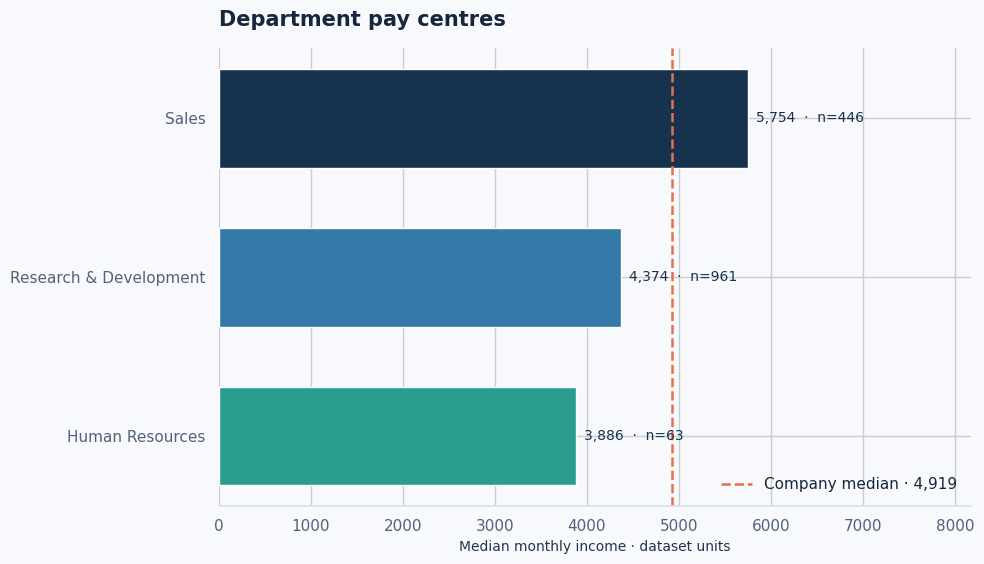

In [14]:
plot_data = department_comp.sort_values("median_income")
fig, ax = plt.subplots(figsize=(10, 5.8))
bars = ax.barh(
    plot_data["Department"],
    plot_data["median_income"],
    color=[TEAL, BLUE, NAVY],
    height=0.62,
)
ax.axvline(income_median, color=CORAL, linestyle="--", linewidth=1.8,
           label=f"Company median · {income_median:,.0f}")
for bar, row in zip(bars, plot_data.itertuples()):
    ax.text(
        bar.get_width() + 85,
        bar.get_y() + bar.get_height() / 2,
        f"{row.median_income:,.0f}  ·  n={row.employees}",
        va="center",
        fontsize=10,
        color=NAVY,
    )
ax.set_title("Department pay centres", loc="left", pad=16)
ax.set_xlabel("Median monthly income · dataset units")
ax.set_ylabel("")
ax.set_xlim(0, plot_data["median_income"].max() * 1.42)
ax.legend(frameon=False, loc="lower right")
sns.despine(ax=ax, left=True)
finish_chart()

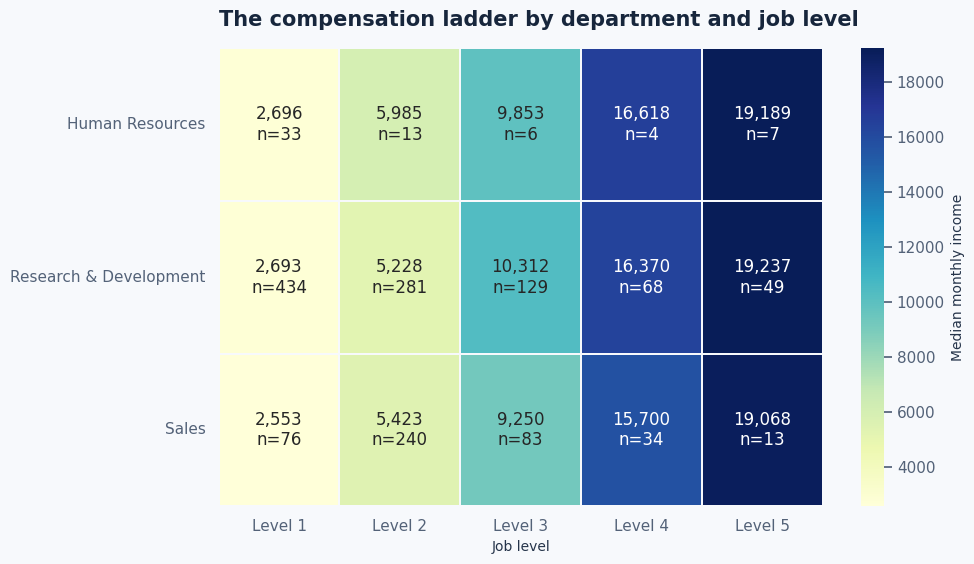

In [15]:
annotation = compensation_pivot.copy().astype(object)
for department in compensation_pivot.index:
    for level in compensation_pivot.columns:
        value = compensation_pivot.loc[department, level]
        count = int(level_count_pivot.loc[department, level])
        annotation.loc[department, level] = f"{value:,.0f}\nn={count}"

fig, ax = plt.subplots(figsize=(10, 5.8))
sns.heatmap(
    compensation_pivot,
    annot=annotation,
    fmt="",
    cmap="YlGnBu",
    linewidths=1.2,
    linecolor="#F7F9FC",
    cbar_kws={"label": "Median monthly income"},
    ax=ax,
)
ax.set_title("The compensation ladder by department and job level", loc="left", pad=16)
ax.set_xlabel("Job level")
ax.set_ylabel("")
ax.set_xticklabels([f"Level {int(x)}" for x in compensation_pivot.columns], rotation=0)
finish_chart()

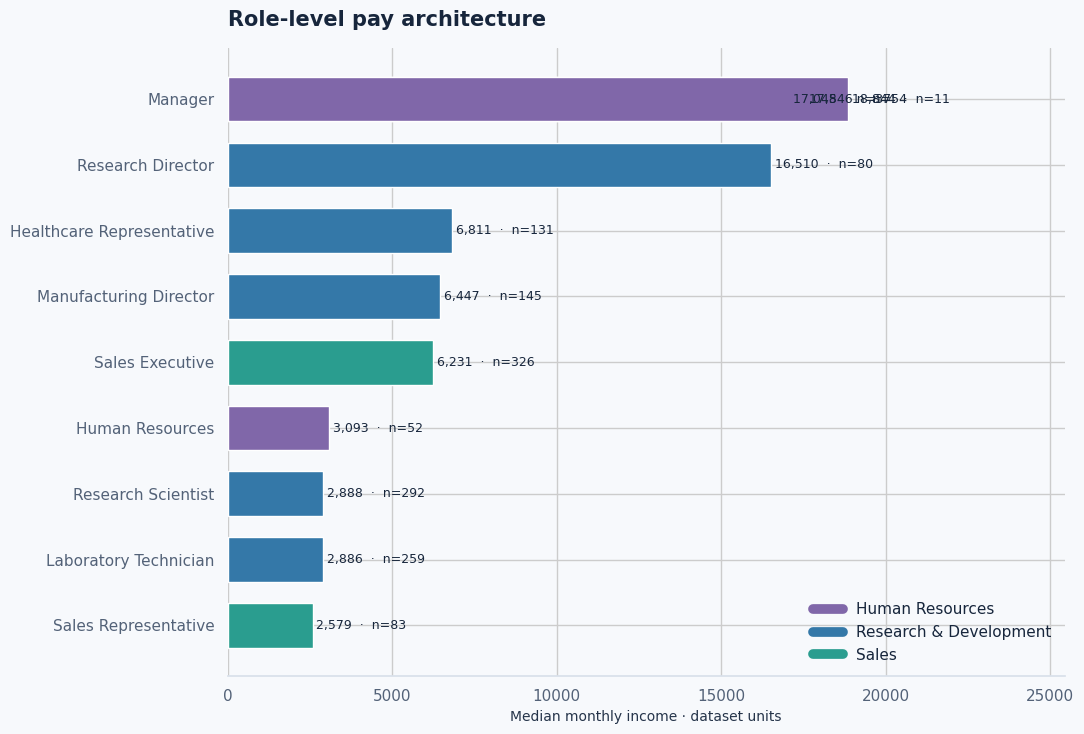

In [16]:
role_plot = role_comp.sort_values("median_income")
department_colors = {
    "Human Resources": PURPLE,
    "Research & Development": BLUE,
    "Sales": TEAL,
}
fig, ax = plt.subplots(figsize=(11, 7.5))
bars = ax.barh(
    role_plot["JobRole"],
    role_plot["median_income"],
    color=role_plot["Department"].map(department_colors),
    height=0.68,
)
for bar, row in zip(bars, role_plot.itertuples()):
    ax.text(
        bar.get_width() + 120,
        bar.get_y() + bar.get_height() / 2,
        f"{row.median_income:,.0f}  ·  n={row.employees}",
        va="center",
        fontsize=9,
    )
legend_handles = [
    plt.Line2D([0], [0], color=color, lw=7, label=department)
    for department, color in department_colors.items()
]
ax.legend(handles=legend_handles, frameon=False, loc="lower right")
ax.set_title("Role-level pay architecture", loc="left", pad=16)
ax.set_xlabel("Median monthly income · dataset units")
ax.set_ylabel("")
ax.set_xlim(0, role_plot["median_income"].max() * 1.35)
sns.despine(ax=ax, left=True)
finish_chart()

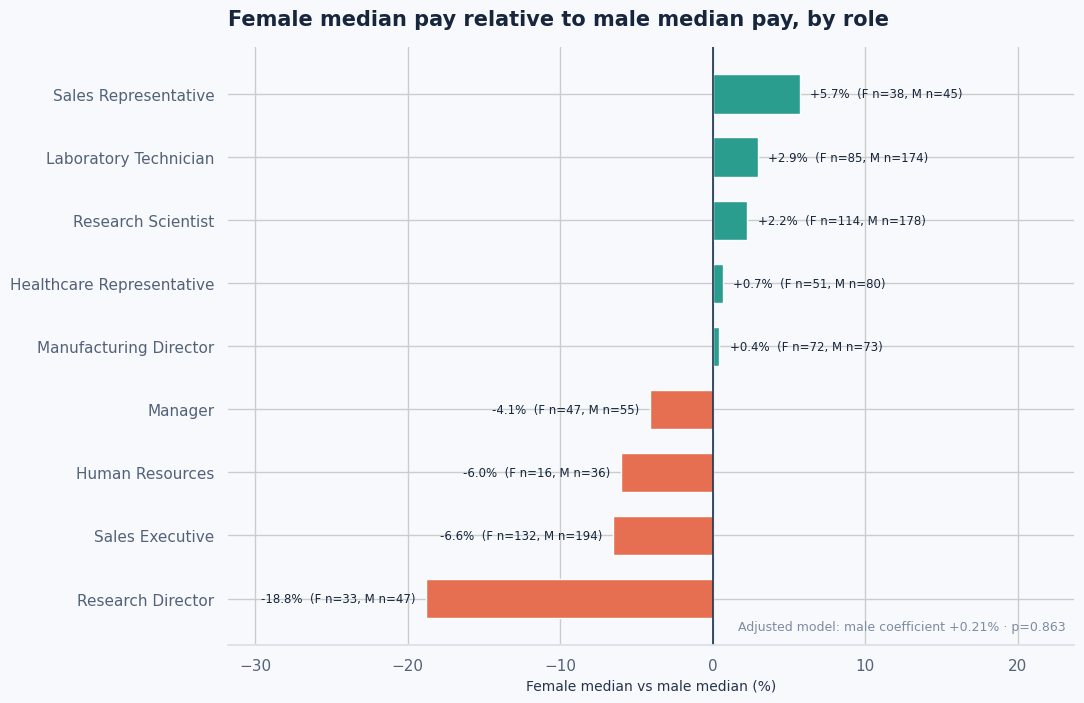

In [17]:
gap_plot = gender_role_gap.sort_values("female_vs_male_pct")
fig, ax = plt.subplots(figsize=(11, 7.2))
colors = [CORAL if value < 0 else TEAL for value in gap_plot["female_vs_male_pct"]]
ax.barh(
    gap_plot["JobRole"],
    gap_plot["female_vs_male_pct"],
    color=colors,
    height=0.62,
)
ax.axvline(0, color=NAVY, linewidth=1.2)
for row in gap_plot.itertuples():
    label = (
        f"{row.female_vs_male_pct:+.1f}%  "
        f"(F n={row.female_employees}, M n={row.male_employees})"
    )
    ax.text(
        row.female_vs_male_pct + (0.7 if row.female_vs_male_pct >= 0 else -0.7),
        row.JobRole,
        label,
        va="center",
        ha="left" if row.female_vs_male_pct >= 0 else "right",
        fontsize=8.5,
    )
ax.set_title("Female median pay relative to male median pay, by role", loc="left", pad=16)
ax.set_xlabel("Female median vs male median (%)")
ax.set_ylabel("")
ax.set_xlim(gap_plot["female_vs_male_pct"].min() - 13,
            gap_plot["female_vs_male_pct"].max() + 18)
ax.text(
    0.99, 0.02,
    f"Adjusted model: male coefficient {adjusted_gender_pct:+.2f}% · p={adjusted_gender_p:.3f}",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color=MUTED,
)
sns.despine(ax=ax, left=True)
finish_chart()

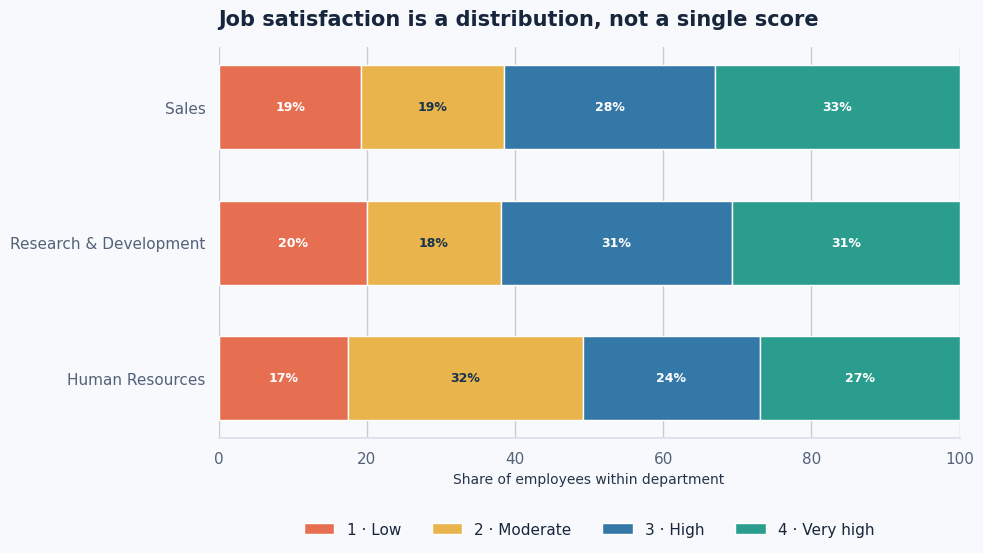

In [18]:
sat_colors = {
    1: CORAL,
    2: GOLD,
    3: BLUE,
    4: TEAL,
}
fig, ax = plt.subplots(figsize=(10, 5.8))
left = np.zeros(len(satisfaction_by_department))
for score in [1, 2, 3, 4]:
    values = satisfaction_by_department[score].to_numpy()
    ax.barh(
        satisfaction_by_department.index,
        values,
        left=left,
        color=sat_colors[score],
        label=f"{score} · {['Low', 'Moderate', 'High', 'Very high'][score-1]}",
        height=0.62,
    )
    for y, (start, value) in enumerate(zip(left, values)):
        if value >= 8:
            ax.text(start + value / 2, y, f"{value:.0f}%",
                    ha="center", va="center", fontsize=9,
                    color="white" if score in [1, 3, 4] else NAVY,
                    fontweight="bold")
    left += values
ax.set_xlim(0, 100)
ax.set_xlabel("Share of employees within department")
ax.set_ylabel("")
ax.set_title("Job satisfaction is a distribution, not a single score", loc="left", pad=16)
ax.legend(ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.18), loc="upper center")
sns.despine(ax=ax, left=True)
finish_chart()

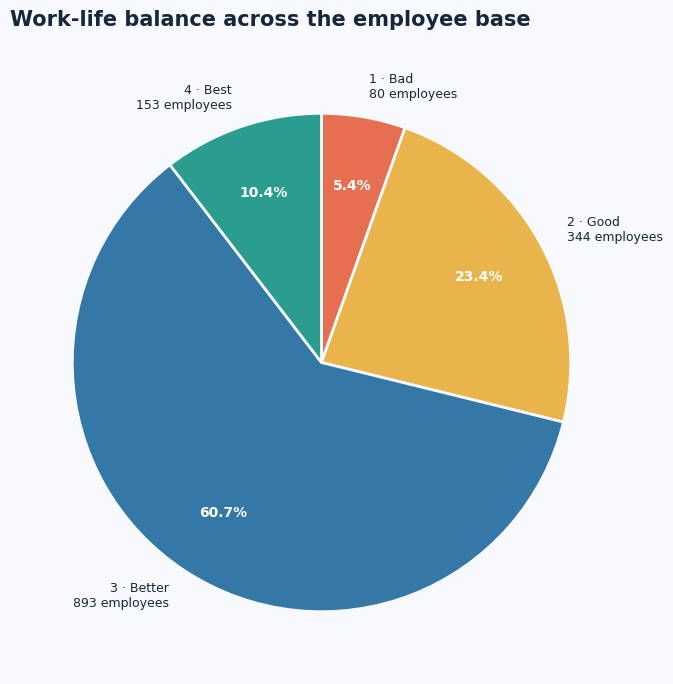

In [19]:
wlb_pie_labels = {
    1: "1 · Bad",
    2: "2 · Good",
    3: "3 · Better",
    4: "4 · Best",
}
pie_values = worklife_overall["employees"].to_numpy()
pie_labels = [
    f"{wlb_pie_labels[int(score)]}\n{count:,} employees"
    for score, count in zip(worklife_overall["WorkLifeBalance"], pie_values)
]
fig, ax = plt.subplots(figsize=(8.5, 7))
wedges, texts, autotexts = ax.pie(
    pie_values,
    labels=pie_labels,
    colors=[CORAL, GOLD, BLUE, TEAL],
    startangle=90,
    counterclock=False,
    autopct=lambda pct: f"{pct:.1f}%",
    pctdistance=0.72,
    labeldistance=1.12,
    wedgeprops={"edgecolor": "#F7F9FC", "linewidth": 2},
    textprops={"fontsize": 9},
)
for item in autotexts:
    item.set_color("white")
    item.set_fontweight("bold")
    item.set_fontsize(10)
ax.set_title("Work-life balance across the employee base", loc="left", pad=18)
finish_chart()

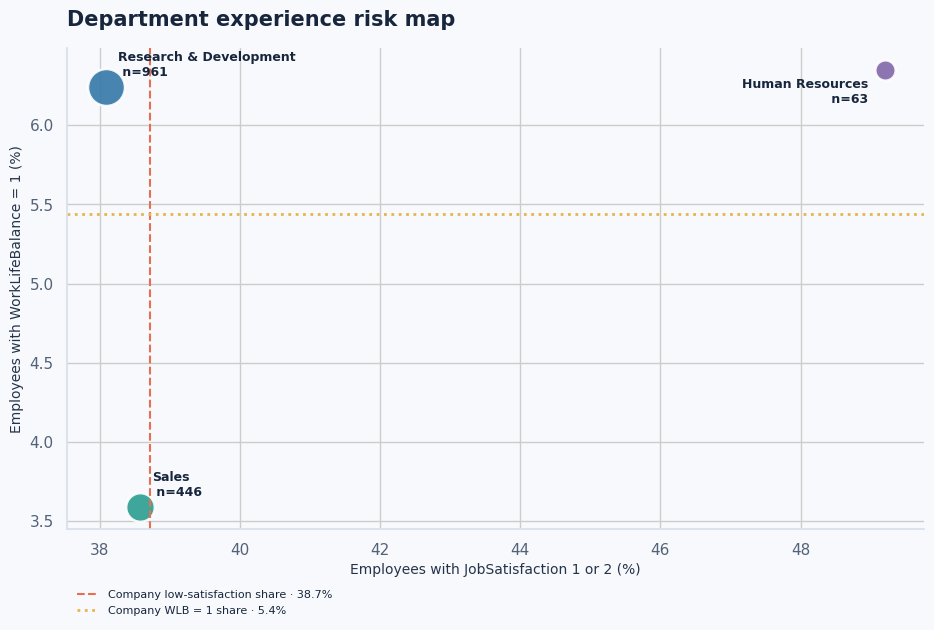

In [20]:
risk_plot = low_satisfaction.merge(
    worklife_flags[["Department", "wlb1_pct", "employees"]],
    on="Department",
    suffixes=("_sat", "_wlb"),
)
fig, ax = plt.subplots(figsize=(9.5, 6.5))
for row in risk_plot.itertuples():
    size = 180 + row.employees_sat * 0.55
    ax.scatter(
        row.low_satisfaction_pct,
        row.wlb1_pct,
        s=size,
        color=department_colors[row.Department],
        edgecolor="white",
        linewidth=1.8,
        alpha=0.9,
    )
    label_offset = (-12, -24) if row.Department == "Human Resources" else (9, 8)
    label_align = "right" if row.Department == "Human Resources" else "left"
    ax.annotate(
        f"{row.Department}\n n={row.employees_sat}",
        (row.low_satisfaction_pct, row.wlb1_pct),
        xytext=label_offset,
        textcoords="offset points",
        ha=label_align,
        fontsize=9,
        fontweight="bold",
    )
ax.axvline(overall_low := hr["JobSatisfaction"].le(2).mean() * 100,
           color=CORAL, linestyle="--", linewidth=1.5,
           label=f"Company low-satisfaction share · {overall_low:.1f}%")
ax.axhline(company_wlb1_share, color=GOLD, linestyle=":", linewidth=2,
           label=f"Company WLB = 1 share · {company_wlb1_share:.1f}%")
ax.set_title("Department experience risk map", loc="left", pad=16)
ax.set_xlabel("Employees with JobSatisfaction 1 or 2 (%)")
ax.set_ylabel("Employees with WorkLifeBalance = 1 (%)")
ax.legend(frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(0.0, -0.20), ncol=1)
sns.despine(ax=ax)
finish_chart()

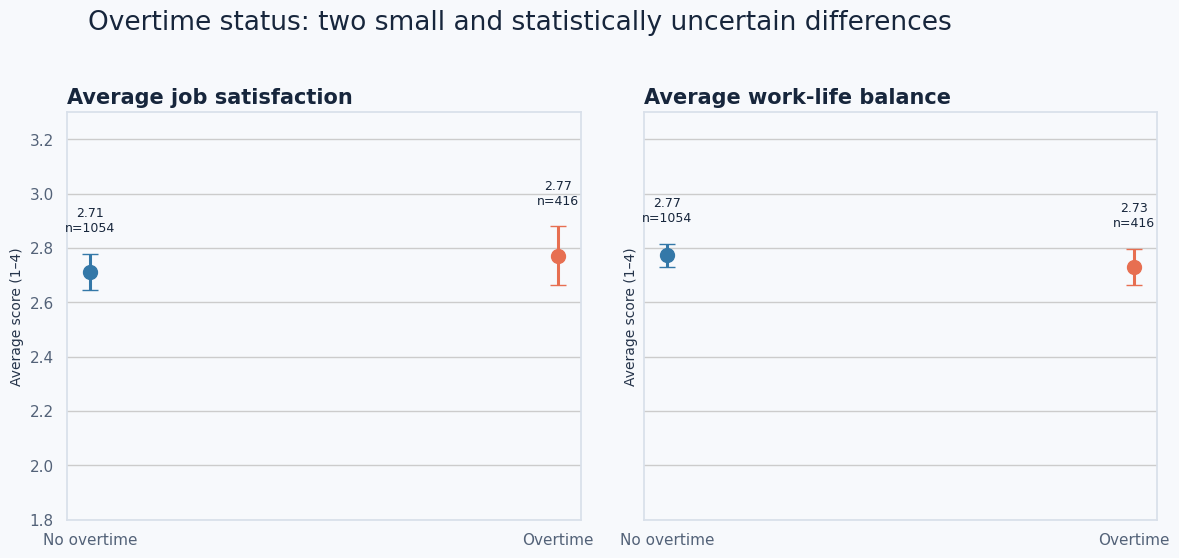

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True)
metrics = [
    ("JobSatisfaction", "Average job satisfaction"),
    ("WorkLifeBalance", "Average work-life balance"),
]
for ax, (metric, title) in zip(axes, metrics):
    for x_pos, label in enumerate(["No", "Yes"]):
        values = hr.loc[hr["OverTime"].eq(label), metric]
        mean_value = values.mean()
        se = values.std(ddof=1) / np.sqrt(len(values))
        margin = 1.96 * se
        color = BLUE if label == "No" else CORAL
        ax.errorbar(
            x_pos, mean_value, yerr=margin,
            fmt="o", markersize=10, capsize=6,
            color=color, ecolor=color, linewidth=2.2,
        )
        ax.text(x_pos, mean_value + margin + 0.07,
                f"{mean_value:.2f}\nn={len(values)}",
                ha="center", va="bottom", fontsize=9)
    ax.set_xticks([0, 1], ["No overtime", "Overtime"])
    ax.set_ylim(1.8, 3.3)
    ax.set_title(title, loc="left")
    ax.set_ylabel("Average score (1–4)")
    ax.grid(axis="x", visible=False)
fig.suptitle("Overtime status: two small and statistically uncertain differences", x=0.08, ha="left", y=1.03)
finish_chart()

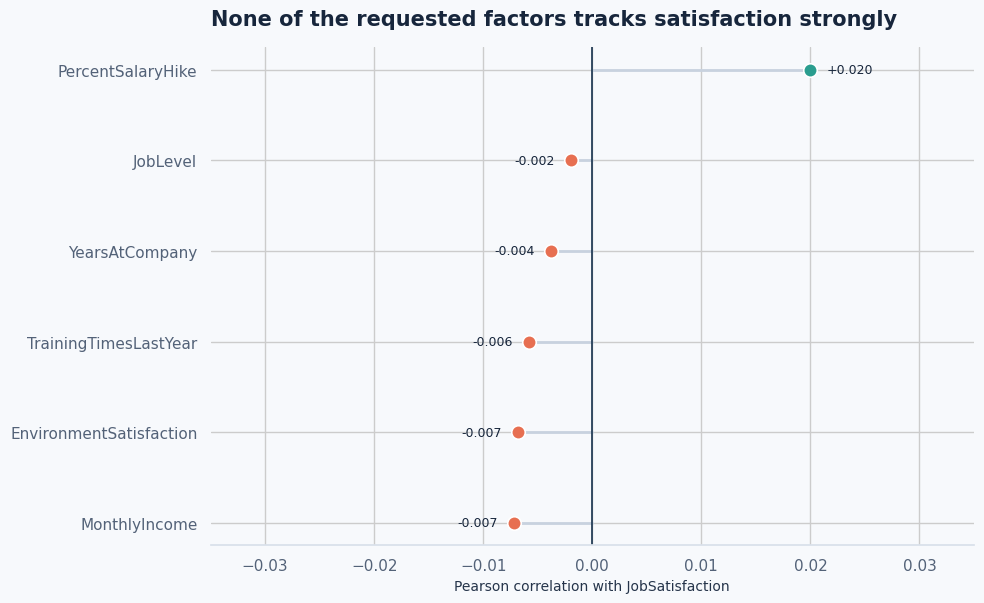

In [22]:
corr_plot = correlation_results.sort_values("pearson_r")
fig, ax = plt.subplots(figsize=(10, 6.2))
for row in corr_plot.itertuples():
    ax.plot(
        [0, row.pearson_r],
        [row.factor, row.factor],
        color="#C8D2DF",
        linewidth=2,
        zorder=1,
    )
    ax.scatter(
        row.pearson_r, row.factor,
        s=95,
        color=TEAL if row.pearson_r >= 0 else CORAL,
        edgecolor="white",
        linewidth=1.2,
        zorder=2,
    )
    ax.text(
        row.pearson_r + (0.0015 if row.pearson_r >= 0 else -0.0015),
        row.factor,
        f"{row.pearson_r:+.3f}",
        va="center",
        ha="left" if row.pearson_r >= 0 else "right",
        fontsize=9,
    )
ax.axvline(0, color=NAVY, linewidth=1.2)
ax.set_xlim(-0.035, 0.035)
ax.set_title("None of the requested factors tracks satisfaction strongly", loc="left", pad=16)
ax.set_xlabel("Pearson correlation with JobSatisfaction")
ax.set_ylabel("")
sns.despine(ax=ax, left=True)
finish_chart()

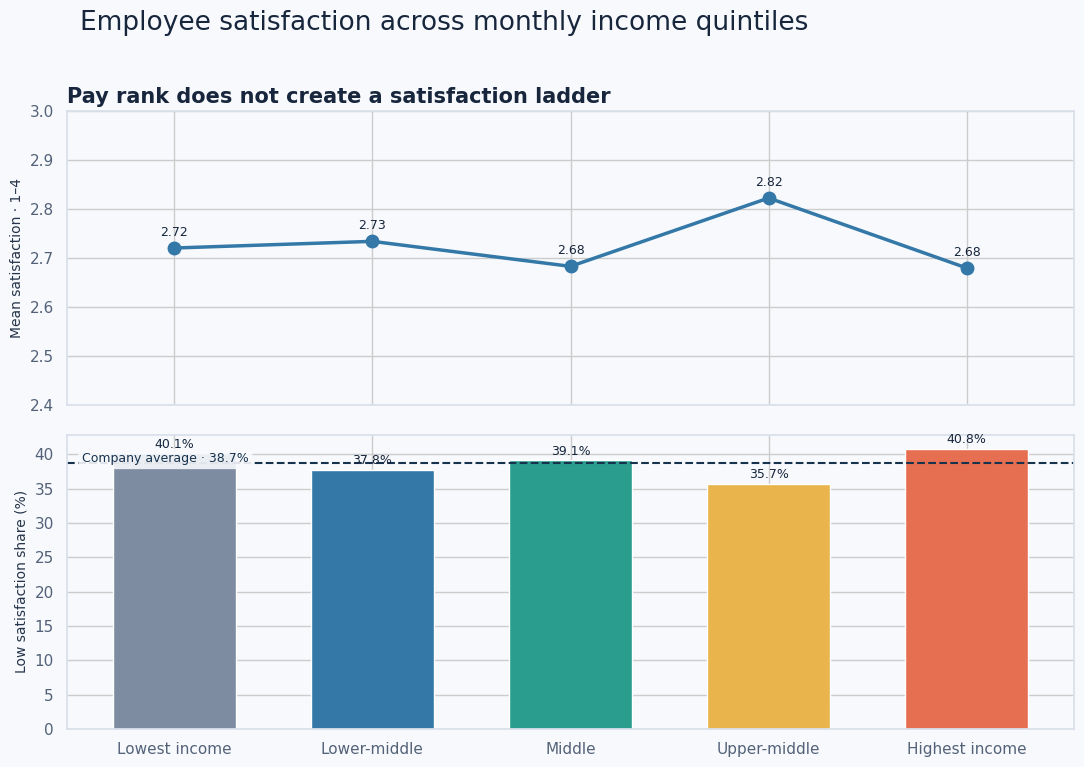

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
x = np.arange(len(income_satisfaction))
labels = income_satisfaction["IncomeBand"].astype(str).tolist()

axes[0].plot(
    x, income_satisfaction["avg_job_satisfaction"],
    marker="o", markersize=9, linewidth=2.5, color=BLUE,
)
axes[0].set_ylim(2.4, 3.0)
axes[0].set_ylabel("Mean satisfaction · 1–4")
axes[0].set_title("Pay rank does not create a satisfaction ladder", loc="left")
for i, value in enumerate(income_satisfaction["avg_job_satisfaction"]):
    axes[0].text(i, value + 0.025, f"{value:.2f}", ha="center", fontsize=9)

axes[1].bar(
    x, income_satisfaction["low_satisfaction_pct"],
    color=[MUTED, BLUE, TEAL, GOLD, CORAL],
    width=0.62,
)
axes[1].axhline(overall_low, color=NAVY, linestyle="--", linewidth=1.5,
                label=f"Company average · {overall_low:.1f}%")
axes[1].set_ylabel("Low satisfaction share (%)")
axes[1].set_xticks(x, labels, rotation=0)
axes[1].text(
    0.015, 0.94,
    f"Company average · {overall_low:.1f}%",
    transform=axes[1].transAxes,
    ha="left",
    va="top",
    fontsize=9,
    color=NAVY,
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "#F7F9FC", "edgecolor": "none", "alpha": 0.9},
)
for i, value in enumerate(income_satisfaction["low_satisfaction_pct"]):
    axes[1].text(i, value + 0.8, f"{value:.1f}%", ha="center", fontsize=9)
fig.suptitle("Employee satisfaction across monthly income quintiles", x=0.08, ha="left", y=1.02)
finish_chart()

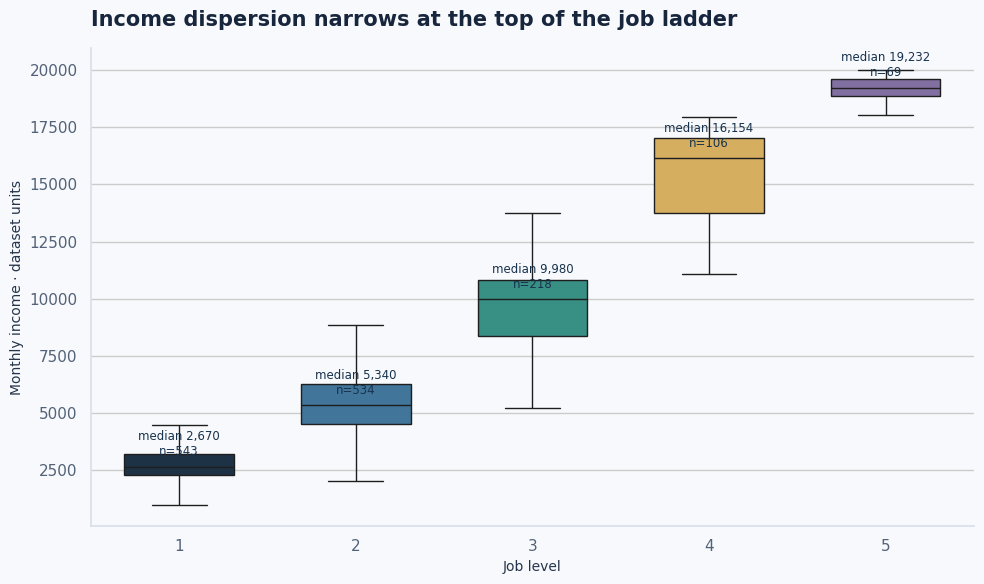

In [24]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=hr,
    x="JobLevel",
    y="MonthlyIncome",
    hue="JobLevel",
    palette=[NAVY, BLUE, TEAL, GOLD, PURPLE],
    legend=False,
    showfliers=False,
    width=0.62,
    ax=ax,
)
for row in level_comp.itertuples():
    ax.text(
        row.JobLevel - 1,
        row.median_income + 360,
        f"median {row.median_income:,.0f}\nn={row.employees}",
        ha="center",
        va="bottom",
        fontsize=8.5,
        color=NAVY,
    )
ax.set_title("Income dispersion narrows at the top of the job ladder", loc="left", pad=16)
ax.set_xlabel("Job level")
ax.set_ylabel("Monthly income · dataset units")
sns.despine(ax=ax)
finish_chart()